# 01 · Pose Extraction

**Goal:** turn every video clip into a sequence of human body keypoints.

We run **YOLO11-pose** (Ultralytics) on each clip at about 10 frames per second. For every sampled frame it finds each person and returns 17 **COCO keypoints** (nose, eyes, ears, shoulders, elbows, wrists, hips, knees, ankles), each with an (x, y) pixel position and a confidence score. The built-in **ByteTrack** tracker gives every person an ID that stays the same across frames, so later we can follow one person through the whole clip.

Output: one compressed `.npz` file per clip in `cache/keypoints/`. This is the slow step (roughly an hour on CPU), so it is **resumable**: clips already cached are skipped when you re-run.

> Kernel: select **Python (pose-shoplifting)** (the project's own virtual environment).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pose_utils as pu

for d in (pu.CACHE_DIR, pu.MODELS_DIR, pu.FIGURES_DIR, pu.RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Dataset folder:", pu.DATA_DIR)

Dataset folder: C:\Users\javier\Desktop\IS424 DATA MINING\Project\cleaned_unified_deduplicated


## 1. The dataset

`manifest.csv` lists every clip with its label, source dataset and fixed train / validation / test split. We add a coarse `source` column (`staged` vs `dcsass`) because the two sources look very different, and we need to keep an eye on that.

In [2]:
manifest = pu.load_manifest()
print(f"{len(manifest)} clips")
pd.crosstab([manifest["source"], manifest["label_name"]], manifest["split"], margins=True)

207 clips


split               test  train  validation  All
source label_name                               
dcsass normal          0      2           2    4
       shoplifting     4     18           2   24
staged normal         15     61          11   87
       shoplifting    14     63          15   92
All                   33    144          30  207

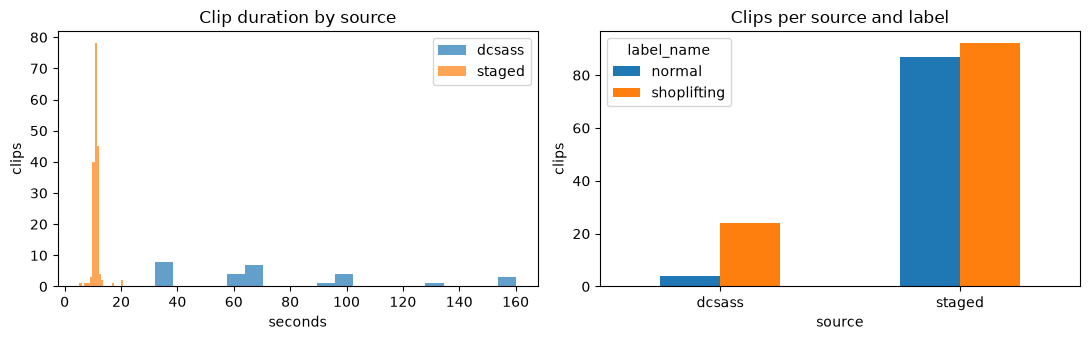

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for src, g in manifest.groupby("source"):
    axes[0].hist(g["duration_seconds"], bins=20, alpha=0.7, label=src)
axes[0].set(title="Clip duration by source", xlabel="seconds", ylabel="clips")
axes[0].legend()
manifest.groupby(["source", "label_name"]).size().unstack().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Clips per source and label", ylabel="clips")
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "01_dataset_overview.png", dpi=150)
plt.show()

**A confound to watch:** the DCSASS clips are long, low-resolution CCTV footage and 24 of the 28 are shoplifting, while the staged clips are short and balanced. A model could learn "looks like DCSASS ⇒ shoplifting" instead of the behaviour itself. Two defences:
1. keypoints are normalised to the person's body size (notebooks 02/03), which removes resolution and camera distance;
2. clip length is never used as a feature.

Notebook 04 reports test results **per source** so we can check whether it worked.

## 2. Load the pose model and time one clip

In [4]:
pose_model = pu.load_pose_model()
sample = manifest.sort_values("duration_seconds").iloc[0]
t0 = time.time()
ext = pu.extract_video(pose_model, sample["video_path"])
dt = time.time() - t0
n = ext["kpts"].shape[0]
print(f"{sample['relative_path']}: {n} sampled frames in {dt:.1f}s ({n / dt:.1f} frames/s)")
print({k: v.shape for k, v in ext.items() if isinstance(v, np.ndarray)})
est_frames = (manifest["duration_seconds"] * pu.TARGET_FPS).sum()
print(f"Whole dataset: ~{est_frames:,.0f} frames -> roughly {est_frames / (n / dt) / 60:.0f} minutes")

videos/normal/normal-40.mp4: 52 sampled frames in 5.5s (9.5 frames/s)
{'kpts': (52, 5, 17, 3), 'boxes': (52, 5, 4), 'track_ids': (52, 5), 'n_people': (52,)}
Whole dataset: ~40,377 frames -> roughly 71 minutes


## 3. Extract every clip (resumable)

In [5]:
todo = manifest[[not Path(p).exists() for p in manifest["cache_path"]]]
print(f"{len(manifest) - len(todo)} already cached, {len(todo)} to extract")
log = []
start = time.time()
for i, row in enumerate(todo.itertuples(), 1):
    t0 = time.time()
    try:
        ext = pu.extract_video(pose_model, row.video_path)
        pu.save_extraction(ext, row.cache_path)
        log.append({"relative_path": row.relative_path, "frames": len(ext["kpts"]), "seconds": time.time() - t0, "error": ""})
    except Exception as e:  # keep going; failures are listed below
        log.append({"relative_path": row.relative_path, "frames": 0, "seconds": time.time() - t0, "error": repr(e)})
    if i % 10 == 0 or i == len(todo):
        print(f"  {i}/{len(todo)} clips, {(time.time() - start) / 60:.1f} min elapsed")
log = pd.DataFrame(log, columns=["relative_path", "frames", "seconds", "error"])
if len(log):
    log.to_csv(pu.RESULTS_DIR / "extraction_log.csv", index=False)
failed = log[log["error"] != ""]
print(f"Failed clips: {len(failed)}")
failed

207 already cached, 0 to extract
Failed clips: 0


,relative_path,frames,seconds,error


## 4. Pose quality check

For each clip we pick the **primary person**: the tracked person seen in the most frames. If the primary person is missing from many frames, or keypoint confidence is low, that clip's pose signal is weak.

In [6]:
rows = []
for row in manifest.itertuples():
    ext = pu.load_extraction(row.cache_path)
    kpts, _, has_person = pu.primary_sequence(ext)
    present = ~np.isnan(kpts[..., 2]).all(axis=1)
    rows.append({
        "relative_path": row.relative_path, "source": row.source, "label_name": row.label_name,
        "frames": len(kpts), "primary_rate": present.mean(), "mean_people": ext["n_people"].mean(),
        "mean_kpt_conf": float(np.nanmean(kpts[present][..., 2])) if present.any() else 0.0,
    })
quality = pd.DataFrame(rows)
quality.to_csv(pu.RESULTS_DIR / "pose_quality.csv", index=False)
print("Clips with nobody detected:", int((quality["primary_rate"] == 0).sum()))
quality.groupby(["source", "label_name"])[["frames", "primary_rate", "mean_people", "mean_kpt_conf"]].mean().round(3)

Clips with nobody detected: 5


frames  primary_rate  mean_people  mean_kpt_conf
source label_name                                                    
dcsass normal       480.000         0.711        1.577          0.792
       shoplifting  773.333         0.469        1.701          0.616
staged normal       112.471         0.905        1.425          0.720
       shoplifting  109.152         0.977        1.405          0.808

## 5. Visual sanity check

Skeletons on the middle frame of one clip per (source, label), picking the first clip where the primary person is visible in most frames. The **primary person is red**, everyone else is grey.

(Some staged "normal" clips show an empty room, so nobody is detected. That is correct, but it makes an uninformative picture.)

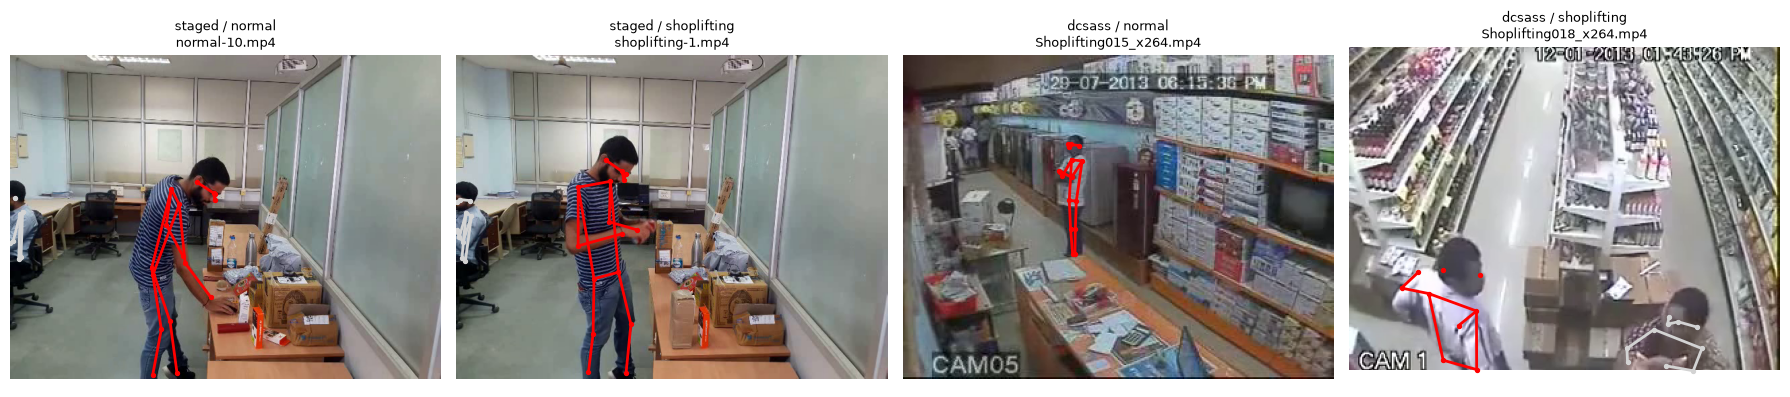

In [7]:
q = quality.set_index("relative_path")
examples = []
for s, l in [("staged", "normal"), ("staged", "shoplifting"), ("dcsass", "normal"), ("dcsass", "shoplifting")]:
    group = manifest[(manifest.source == s) & (manifest.label_name == l)]
    good = group[q.loc[group["relative_path"], "primary_rate"].to_numpy() >= 0.8]
    examples.append((good if len(good) else group).head(1))
examples = pd.concat(examples)
fig, axes = plt.subplots(1, len(examples), figsize=(4.5 * len(examples), 4))
for ax, row in zip(axes, examples.itertuples()):
    ext = pu.load_extraction(row.cache_path)
    pu.draw_pose_frame(ax, row.video_path, ext, len(ext["kpts"]) // 2)
    ax.set_title(f"{row.source} / {row.label_name}\n{Path(row.relative_path).name}", fontsize=9)
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "01_pose_examples.png", dpi=150)
plt.show()